# Human Activities - Classification

Pour ce TP nous allons mettre en pratique plusieurs méthodes de classification supervisée sur des données d'enregistrement d'acceleromètres (de smart-phones).

Les données sources sont disponibles sur [ici](http://bertrand.michel.perso.math.cnrs.fr/Enseignements/Data/UCI-HAR-Dataset.zip), voir aussi la description sur le site de [la plateforme de données UCI](https://archive.ics.uci.edu/ml/datasets/human+activity+recognition+using+smartphones).

"The experiments have been carried out with a group of 30 volunteers within an age bracket of 19-48 years. Each person performed six activities (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, LAYING) wearing a smartphone (Samsung Galaxy S II) on the waist. Using its embedded accelerometer and gyroscope, we captured 3-axial linear acceleration and 3-axial angular velocity at a constant rate of 50Hz. The experiments have been video-recorded to label the data manually.

The sensor signals (accelerometer and gyroscope) were pre-processed by applying noise filters and then sampled in fixed-width sliding windows of 2.56 sec and 50% overlap (128 readings/window). The sensor acceleration signal, which has gravitational and body motion components, was separated using a Butterworth low-pass filter into body acceleration and gravity. The gravitational force is assumed to have only low frequency components, therefore a filter with 0.3 Hz cutoff frequency was used. From each window, a vector of features was obtained by calculating variables from the time and frequency domain. See 'features_info.txt' for more details."

L'objectif de ce TP est de retrouver l'activité à partir de toutes ces descripteurs (features). Notez que dans un contexte plus réaliste il vous faudrait créer par vous même tous ces features qui décrivent les séries temporelles des accelerations enregistrées.


In [1]:
%matplotlib inline
from pylab import *
import pandas as pd
from sklearn.decomposition import PCA
from sklearn import preprocessing
from sklearn.preprocessing import scale
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold, cross_val_score
from sklearn import neighbors, model_selection
from numpy import mean

# Importation des données


Les commandes suivantes permettent de récupérer les données.
Pour simplifier on n'utilise pour le TP que les données du dossier "train".

> Vérifiez que vous comprenez l'ensemble des commandes ci-dessous.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
votre_path = '/content/drive/My Drive/UCI HAR Dataset/'

In [4]:
data_path = votre_path + "train/X_train.txt"
activity_features = pd.read_csv(data_path, delim_whitespace=True, header=None)

<ipython-input-4-c2c72a4998d7>:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  activity_features = pd.read_csv(data_path, delim_whitespace=True, header=None)


#### Importation des features

In [ ]:
data_path = votre_path + "train/X_train.txt"
activity_features = pd.read_csv(data_path,delim_whitespace=True,
                                header=None)
activity_features.head(28)

<ipython-input-5-e3648f3c5fb7>:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  activity_features = pd.read_csv(data_path,delim_whitespace=True,


,0,1,2,3,4,5,6,7,8,9,...,551,552,553,554,555,556,557,558,559,560
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892
5,0.277199,-0.010098,-0.105137,-0.997335,-0.990487,-0.995420,-0.997627,-0.990218,-0.995549,-0.942469,...,0.019953,-0.545410,-0.844619,0.082632,-0.143439,0.275041,-0.368224,-0.849632,0.184823,-0.042126
6,0.279454,-0.019641,-0.110022,-0.996921,-0.967186,-0.983118,-0.997003,-0.966097,-0.983116,-0.940987,...,0.145844,-0.217198,-0.564430,-0.212754,-0.230622,0.014637,-0.189512,-0.852150,0.182170,-0.043010
7,0.277432,-0.030488,-0.125360,-0.996559,-0.966728,-0.981585,-0.996485,-0.966313,-0.982982,-0.940987,...,0.136382,-0.082307,-0.421715,-0.020888,0.593996,-0.561871,0.467383,-0.851017,0.183779,-0.041976
8,0.277293,-0.021751,-0.120751,-0.997328,-0.961245,-0.983672,-0.997596,-0.957236,-0.984379,-0.940598,...,0.314038,-0.269401,-0.572995,0.012954,0.080936,-0.234313,0.117797,-0.847971,0.188982,-0.037364
9,0.280586,-0.009960,-0.106065,-0.994803,-0.972758,-0.986244,-0.995405,-0.973663,-0.985642,-0.940028,...,0.267383,0.339526,0.140452,-0.020590,-0.127730,-0.482871,-0.070670,-0.848294,0.190310,-0.034417


#### Importation des activités :

In [ ]:
data_path = votre_path + "train/y_train.txt"
activity  =    pd.read_csv(data_path,delim_whitespace=True,header=None)
activity  =  activity.values[:,0] -  1
# la première activité sera 0 (plus pratique en python)
activity_names = ['WALKING','WALKING_UPSTAIRS','WALKING_DOWNSTAIRS','SITTING','STANDING','LAYING']
print(activity)

[4 4 4 ... 1 1 1]


<ipython-input-6-0907e7b2dd6d>:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  activity  =    pd.read_csv(data_path,delim_whitespace=True,header=None)


La variable à prédire  est la variable d'activité. Il s'agit donc d'un problème de classification (à 6 classes).
Pour cela on dispose des variables du tableau `activity_features`.
> Combien de variables sont disponibles pour construire le prédicteur de l'activité ?  De combien d'observations dispose-t-on ?

In [ ]:
nbre_de_variables = activity_features.shape[1]
nbre_observations = activity_features.shape[0]
print(f"Nbre de variables: {nbre_de_variables}")
print(f"Nbre d'observations: {nbre_observations}")

Nbre de variables: 561
Nbre d'observations: 7352


Pour de nombreux méthodes d'appprentissage statistique, il est conseiller de préalablement standardiser les données.

> Effectuer une standardisation des features (activity_features) avec la fonction  [scale()](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.scale.html) de scikit-learn.

In [ ]:
features_nor = scale(activity_features)
features_nor

array([[ 0.20064157, -0.0636826 , -0.41962845, ..., -0.68721921,
         0.40794614, -0.00756789],
       [ 0.05594788,  0.03148567, -0.25390836, ..., -0.694138  ,
         0.40911698,  0.00787517],
       [ 0.07351535, -0.04341648, -0.07629468, ..., -0.702239  ,
         0.4102883 ,  0.02650234],
       ...,
       [-0.01566765,  0.0167814 ,  1.13222107, ..., -0.56584847,
         0.64059683,  0.34870928],
       [ 0.21586648, -0.02812252, -0.86770988, ..., -0.57766781,
         0.63147758,  0.29327564],
       [ 1.09620157,  0.12919873, -1.67268082, ..., -0.57392691,
         0.63274259,  0.33396081]])

#### Importation des sujets :

In [ ]:
data_path = votre_path + "train/subject_train.txt"
sujet =  pd.read_csv(data_path,delim_whitespace=True,header=None)
sujet =sujet.values[:,0]
print(sujet)

[ 1  1  1 ... 30 30 30]


<ipython-input-9-5bf9fca74079>:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  sujet =  pd.read_csv(data_path,delim_whitespace=True,header=None)


A chaque sujet correspond plusieurs observations.
> Indiquer le nombre d'observations de chaque sujet

In [ ]:
observation_counts = pd.Series(sujet).value_counts().sort_index()
print(observation_counts)

1     347
3     341
5     302
6     325
7     308
8     281
11    316
14    323
15    328
16    366
17    368
19    360
21    408
22    321
23    372
25    409
26    392
27    376
28    382
29    344
30    383
Name: count, dtype: int64


# Problème de classification à deux classes

Dans toute la première partie du TP, on considère un problème de classification à deux classes.

> Extraire les donnnés pour les activités  'SITTING'(activity = 3)  et 'STANDING'  (activity =4) uniquement. On appele `features34` et `activity34` les données correspondantes.

In [ ]:
n, p = features_nor.shape
index_act34 = [i for i in range(n) if activity[i] == 3 or activity[i] == 4]
activity34 = activity[index_act34]
features34 = features_nor[index_act34]
print(features34.shape)

(2660, 561)


# Présélection de features  pour réduire la dimension (screening)

Pour diminuer les temps de calul on peut pré-sélectionner les 100 features les plus discriminants via un critère univarié.

> Utiliser le critère  [SelectKBest](http://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html) basé sur la F-value (variance inter / variance intra).

Attention, cette méthode ne garantit en rien que l'on a choisi le "meilleur" groupe de 100 variables pour le problème de classification.

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

Selec = SelectKBest(f_classif, k=100)
features34 = Selec.fit_transform(features34, activity34)
print(features34.shape)

(2660, 100)


# Ajustement et prédiction pour des méthodes classiques de classification

> Pour chacune des méthodes de classificiation listées ci-dessous, ajuster un predicteur de l'activité en utilisant comme données d'apprentissage la base (features34,activity34) :      
- Classifieur naif bayesien avec la fonction `GaussianNB()`   
- Classifieur des k plus proches voisins avec `neighbors.KNeighborsClassifier()` avec 5 plus proches voisins.  
- Classifieur par régression logistique avec pénalisation ridge, en utilisant la fonction `linear_model.LogisticRegression() `. Indiquer la pénalité "l2" dans les arguments de la fonction et choisir le solveur "saga" (voir la doc de la fonction).


Une présentation de chacune des ces fonctions est disponible sur cette [page](http://scikit-learn.org/stable/user_guide.html).
</p>

In [ ]:
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
gnb.fit(features34, activity34)


from sklearn import neighbors
nn = neighbors.KNeighborsClassifier(n_neighbors=5)
nn.fit(features34, activity34)


from sklearn import linear_model
logit = linear_model.LogisticRegression(penalty='l2', solver='saga')  # Initialize Logistic Regression with L2 penalty and saga solver
logit.fit(features34, activity34)  # Fit the model

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticRegression(solver='saga')

Pour chacune de ces méthodes, on peut faire une prédiction grâce à la méthode `predict()`. par exemple pour le classifieur naif bayesien :

In [ ]:
feat_pred_gnb = gnb.predict(features34)
print(feat_pred_gnb)

[3 3 4 ... 3 3 3]


> Faire de même une prédiction pour le classifieur des plus proches voisins et pour la régression logistique.

In [ ]:
# K-Nearest Neighbors predictions
feat_pred_knn = nn.predict(features34)
print(feat_pred_knn)

# Logistic Regression predictions
feat_pred_logit = logit.predict(features34)
print(feat_pred_logit)

[4 4 4 ... 3 3 3]
[4 4 4 ... 3 3 3]


> Ces prédictions sont-elles cohérentes entre elles ?

Predictions similaires entre la regression logistique et le KNN

[texte du lien](https://)

> Pour chaque prédicteur :
> - Calculer le taux d'erreur "à la main" en comparant les observations et les prédictions.
> - Calculer le taux de bon classement avec la méthode `score()` (disponible pour tout predicteur)

In [ ]:
#error rate on hand
# Gaussian Naive Bayes
error_rate_gnb = sum(feat_pred_gnb != activity34) / len(activity34)
print(f"Taux d'erreur GNB: {error_rate_gnb:.4f}")

# K-Nearest Neighbors
error_rate_knn = sum(feat_pred_knn != activity34) / len(activity34)
print(f"Taux d'erreur KNN: {error_rate_knn:.4f}")

# Logistic Regression
error_rate_logit = sum(feat_pred_logit != activity34) / len(activity34)
print(f"Taux d'erreur Logit: {error_rate_logit:.4f}")

Taux d'erreur GNB: 0.1944
Taux d'erreur KNN: 0.0391
Taux d'erreur Logit: 0.0410


In [ ]:
#Error rate from score
# Gaussian Naive Bayes
error_rate_gnb = 1 - accuracy_score(activity34, feat_pred_gnb)
accuracy_gnb = gnb.score(features34, activity34)
# K-Nearest Neighbors
error_rate_knn = 1 - accuracy_score(activity34, feat_pred_knn)
accuracy_knn = nn.score(features34, activity34)
# Logistic Regression
error_rate_logit = 1 - accuracy_score(activity34, feat_pred_logit)
accuracy_logit = logit.score(features34, activity34)

print(f"Gaussian Naive Bayes: Error Rate = {error_rate_gnb:.4f}, Accuracy = {accuracy_gnb:.4f}")
print(f"K-Nearest Neighbors: Error Rate = {error_rate_knn:.4f}, Accuracy = {accuracy_knn:.4f}")
print(f"Logistic Regression: Error Rate = {error_rate_logit:.4f}, Accuracy = {accuracy_logit:.4f}")

Gaussian Naive Bayes: Error Rate = 0.1944, Accuracy = 0.8056
K-Nearest Neighbors: Error Rate = 0.0391, Accuracy = 0.9609
Logistic Regression: Error Rate = 0.0410, Accuracy = 0.9590


Evidemment ce n'est pas pas la bonne façon d'estimer le risque de l'estimateur : estimer de l'erreur de généralisation en évaluant les erreurs sur l'échantillon qui a déjà servi à ajuster le prédicteur conduit la plupart du temps à une estimation trop optimiste.

# Evaluation de l'erreur par découpage train / test

Nous allons maintenant évaluer l'erreur de généralisation en conservant une partie de l'échantillon pour évaluer les erreurs du prédicteur ajusté. Pour cela on découpe aléatoirement l'échantillon initial en deux parties :  

- l'ensemble d'apprentissage : utilisé pour ajuster les prédicteurs ;
- l'ensemble de test (ou de validation) : utilisé pour évaluer les performances des prédicteurs.

> Utiliser la fonction <code>train_test_split</code> du module [<code>model_selection</code>](http://scikit-learn.org/stable/modules/classes.html#module-sklearn.model_selection) pour construire un échantillon d'apprentissage de taille 60% (et donc 40% réservées aux données de test)

In [ ]:
from sklearn.model_selection import train_test_split

features_train, features_test, activity_train, activity_test = train_test_split(
    features34, activity34, test_size=0.4, random_state=0
)

print(len(activity_train) / float(len(activity34)))
print(len(activity_test) / float(len(activity34)))
print(features_test.shape)

0.6
0.4
(1064, 100)


> Evaluer le risque d'un classifieur par plus proches voisins (knn) avec 5 voisins sur ce découpage des données : ajuster sur les données d'apprentissage et évaluer les erreurs sur le test.  
>
> Vérifier que l'estimation de l'erreur ainsi obtenue est plus élevée que l'estimation obtenue précédemment, en ajustant et évaluant l'erreur sur le même échantillon (échantillon complet, sans découpage)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Create and train the KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(features_train, activity_train)

# Predict on the test
predictions_test = knn.predict(features_test)

#  error rate on the test
error_rate_test = 1 - accuracy_score(activity_test, predictions_test)

#  error rate on the full sample
predictions_full = knn.predict(features34)
error_rate_full = 1 - accuracy_score(activity34, predictions_full)
print(f"Error rate on test set: {error_rate_test:.4f}")
print(f"Error rate on full sample: {error_rate_full:.4f}")
# Checking if the test error is higher than the full sample error
print(f"Test error is higher than full sample error: {error_rate_test > error_rate_full}")

Error rate on test set: 0.1109
Error rate on full sample: 0.0771
Test error is higher than full sample error: True


> Reproduire la procédure 100 fois et dresser le boxplot de l'estimation de l'erreur sur ces 100 runs.

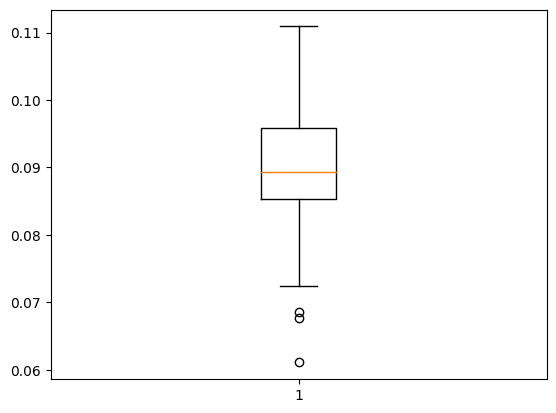

In [ ]:
score_train_test = []
for simu in range(100):
    features_train, features_test, activity_train, activity_test = train_test_split(
        features34, activity34, test_size=0.4, random_state=simu
    )
    nn_train_test = KNeighborsClassifier(n_neighbors=5)
    nn_train_test.fit(features_train, activity_train)
    activity_pred_test = nn_train_test.predict(features_test)
    accuracy_test = accuracy_score(activity_test, activity_pred_test)
    score_train_test.append(1 - accuracy_test)  # backup of error rate
B = plt.boxplot(score_train_test)
plt.show()

> Tracer la courbe d'erreur du classifieur par plus proches voisins en fonction du nombre de voisins utilisés (de 1 à 15), en utilisant cette méthode de découpage train / test répétée 20 fois.

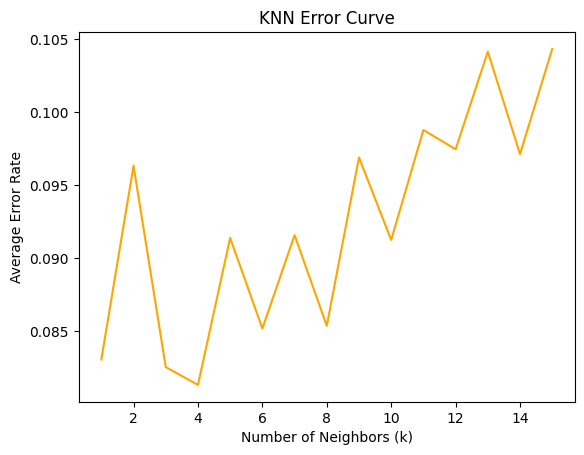

In [ ]:
neighbors_range = range(1, 16)
# repetitions
num_repetitions = 20
# Store error rates for each neighbor value
error_rates = []

for k in neighbors_range:
    # Repeat the train/test split 20 times
    temp_error_rates = []
    for _ in range(num_repetitions):
        # Split data
        features_train, features_test, activity_train, activity_test = train_test_split(
            features34, activity34, test_size=0.4)

        # Create and train KNN classifier
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(features_train, activity_train)

        # Predict on test set and calculate error rate
        predictions = knn.predict(features_test)
        error_rate = 1 - accuracy_score(activity_test, predictions)
        temp_error_rates.append(error_rate)

    # Store average error rate for the current k
    error_rates.append(np.mean(temp_error_rates))

# Plot the error curve
plt.plot(neighbors_range, error_rates,color='orange')
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Average Error Rate")
plt.title("KNN Error Curve")
plt.show()

En réalité, si l'on désire une estimation du modèle sélectionné ainsi, il faut découper l'échantillon disponible non pas en deux mais en trois parties :
- l'ensemble d'apprentissage : utilisé pour construire des modèles ;
- l'ensemble de validation : utilisé pour choisir un modèle ;
- l'ensemble de test : utilisé pour évaluer les performances du modèle
  finalement choisi.
  
Ceci est notamment important lorsque l'on souhaite comparer deux méthodes qui ont toutes les deux fait intervenir un réglage de paramètres (ici le nombre de voisins).

> **Question bonus** (finir le tp avant de répondre à cette question) : Mettre en oeuvre cette méthode pour estimer l'erreur de généralisation du prédicteur knn pour lequel le nombre de voisins est choisi via l'échantillon de validation.

# Estimation du risque par validation croisée

On présente ci-dessous la méthode du de validation croisée de type **k-fold**.

L'idée principale est de faire jouer à chaque observation à la fois le rôle de donnée d'apprentissage et celui de donnée de validation.

Le principe consiste à partitionner aléatoirement les données $D=(\mathbf{x}_i,y_i)_{1\leq i\leq N} $
en $K$ blocs disjoints de tailles comparables :
$D^1,\ldots,D^K$. On prend généralement $K=5$ ou $10$. La méthode du **leave-one-out (Loo)** correspond au choix $K=N$.

On estime alors la qualité d'un predicteur $\hat f$ de la
façon suivante :
- pour tout $k \in \{1,\dots, K\}$, on construit un predicteur $\hat f^k$ (du même type que $\hat f$) sur l'ensemble d'apprentissage $D^{-k} := D\setminus D^k$ ;
- on estime le risque du prédicteur $\hat f$ par   
$$
\frac{1}{N}\sum_{k=1}^K\sum_{\mathbf{x}_i\in D^k} \ell(\hat f^k(\mathbf{x}_i),y_i),
$$
où $\ell$ est la perte utilisée.

On construit donc autant de prédicteurs qu'il y a de blocs dans
l'ensemble d'apprentissage. Chaque prédicteur est évalué sur les éléments du
bloc qui n'a pas été utilisé pour l'apprentissage (et qui joue donc le rôle d'
ensemble de validation).

Lorsque l'on souhaite régler un paramètre en utilisant la validation croisée, par exemple le nombre de voisins $k$ pour knn, on procède comme suit :
- on évalue les performances des prédicteurs par validation croisée comme expliqué ci-dessus ;
- on détermine la valeur optimale du paramètre ;
- on construit finalement un predicteur pour le paramètre sélectionné, en utilisant comme base d'apprentissage toutes les données.


**Comparaison entre LOO et methodes k folds, quelques repères :**
- LOO a un coût computationnel plus élevé que les méthodes k-fold pour k petit (pour k = 5 ou 10 par exemple)
- L'estimation de l'erreur fournie par LOO a généralement une variance plus élevée que celles obtenues par un k-fold pour k petit.
- En revanche, si l'erreur de classification décroit très rapidement avec $n$, les méthodes k-fold avec k petit peuvent surestimer significativement l'erreur de généralisation.
- En général, il est souvent recommandé d'utiliser les méthodes k-fold avec k = 5 ou 10.

L'ensemble des méthodes de validation croisée disponibles sous `sklearn` sont disponibles dans le module [<code>model_selection</code>](http://scikit-learn.org/stable/modules/classes.html#module-sklearn.model_selection). Voir aussi le [guide](https://scikit-learn.org/stable/modules/cross_validation.html#).

##  Estimation de l'erreur par 10-fold :

In [ ]:
nn_val_croisee = neighbors.KNeighborsClassifier(n_neighbors = 10)
scores = model_selection.cross_val_score(nn_val_croisee, features34, activity34, cv=10)
print(scores)
print(mean(scores))

[0.90601504 0.83458647 0.85338346 0.81578947 0.87593985 0.80451128
 0.91353383 0.95864662 0.84586466 0.88345865]
0.8691729323308272


Attention cependant, avec cette méthode, la fonction `cross_val_score` ne permute pas préalablement les données avant de définir les blocs. Voir cette [note](https://scikit-learn.org/stable/modules/cross_validation.html#a-note-on-shuffling) dans la doc de sklearn.

> Modifier la procédure pour que les données soient bien initiallement permutées. On utilise pour cela un "iterateur" de validation croisée, que l'on définit ici avec la fonction `KFold`, et que l'on fournit en argument de la fonction `cross_val_score`.

In [ ]:
my_kfold = model_selection.KFold(n_splits=10, shuffle=True)

nn_val_croisee = neighbors.KNeighborsClassifier(n_neighbors = 10)

scores = model_selection.cross_val_score(estimator=nn_val_croisee,
                        X=features34,
                        y=activity34,
                        cv=my_kfold,
                        n_jobs=-1) # permet de répartir les calculs sur plusieurs coeurs
print(scores)
print(mean(scores))

[0.90977444 0.93984962 0.93609023 0.93984962 0.91353383 0.91353383
 0.90225564 0.89849624 0.93609023 0.92105263]
0.9210526315789472


##  Estimation de l'erreur par Loo


> Utiliser la fonction <code>LeaveOneOut</code> de `model_selection` pour évaluer l'erreur du classifieur de plus proches voisin (pour 10 voisins).



In [ ]:
from sklearn.model_selection import LeaveOneOut

# Create LeaveOneOut object
loo = LeaveOneOut()

# Create KNN classifier with 10 neighbors
nn_loo = neighbors.KNeighborsClassifier(n_neighbors=10)

# Perform Leave-One-Out cross-validation
scores = model_selection.cross_val_score(nn_loo, features34, activity34, cv=loo, n_jobs=-1)

# average accuracy
print("Average accuracy:", scores.mean())

#  error rate
error_rate = 1 - scores.mean()
print("Error rate:", error_rate)

Average accuracy: 0.9278195488721804
Error rate: 0.07218045112781957


> La question de la permutation aléatoire initiale des données se pose-t-elle ici aussi ?

En effet, LeaveOneOut considère déjà chaque point de données comme un ensemble de test distinct, créant ainsi une permutation où chaque point de données est exclu une fois. Par conséquent, une permutation aléatoire supplémentaire n'est pas nécessaire.

## Sélection du nombre de plus proches voisins par validation croisée 10 fold

Selectionner un nombre de voisins pour le classifieur de plus proches voisins par validation croisée 10 fold.

In [ ]:
# Define the range of neighbors to consider
neighbors_range = range(1, 21)

# Create KFold object for 10-fold cross-validation
kf = KFold(n_splits=10, shuffle=True)

# Store accuracy scores for each neighbor value
accuracy_scores = []

# Iterate over different neighbor values
for k in neighbors_range:
    # Store scores for each fold
    fold_scores = []

    # Iterate over folds
    for train_index, val_index in kf.split(features34):
        # Split data into training and validation sets
        X_train, X_val = features34[train_index], features34[val_index]
        y_train, y_val = activity34[train_index], activity34[val_index]

        # Create and train KNN classifier
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train, y_train)

        # Predict on validation set and calculate accuracy
        y_pred = knn.predict(X_val)
        accuracy = accuracy_score(y_val, y_pred)
        fold_scores.append(accuracy)

    # Calculate average accuracy for the current neighbor value
    accuracy_scores.append(np.mean(fold_scores))

#  best number of neighbors
best_k = neighbors_range[np.argmax(accuracy_scores)]
print("Best number of neighbors:", best_k)

#  best accuracy score
print("Best accuracy score:", np.max(accuracy_scores))

Best number of neighbors: 1
Best accuracy score: 0.9372180451127818


## La fonction GridSearchCV

En apprentissage statistique, on a très souvent recours à la validation croisée pour régler des paramètres de la méthode utilisée. La fonction [gridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) permet d'effectuer cette tâche de façon simple, en répartissant éventuellement les calculs sur plusieurs coeurs (voir plus bas).

In [ ]:
from sklearn.model_selection import GridSearchCV
from time import time

# la grille de parametres a regler sont definis dans un dictionnaire (dict)
tuned_parameters = {'n_neighbors': range(2,20)}
start = time()

my_kfold = model_selection.KFold(n_splits=10, shuffle=True, random_state=0)
nnGrid = GridSearchCV(neighbors.KNeighborsClassifier(),
                      tuned_parameters,
                      cv=5)
nnGrid.fit(features34, activity34)
print(str(time() - start)+ " sec")

# best
print(nnGrid.best_params_)

2.393759250640869 sec
{'n_neighbors': 14}


> Si votre machine le permet, utiliser maintenant plusieurs coeurs (argument "n_jobs= ") et comparer les temps de calcul.

In [ ]:
from sklearn.model_selection import GridSearchCV
from time import time

# Define the range of neighbors to consider
tuned_parameters = {'n_neighbors': range(2, 20)}

# Record start time
start_time = time()

#(use all available cores)
nnGrid = GridSearchCV(neighbors.KNeighborsClassifier(), tuned_parameters, cv=5, n_jobs=-1)
nnGrid.fit(features34, activity34)

# Record end time and calculate elapsed time
end_time = time()
elapsed_time_parallel = end_time - start_time

#  best model and elapsed time
print("Best model:", nnGrid.best_params_)
print("Elapsed time (parallel):", elapsed_time_parallel, "seconds")

# without parallel processing (n_jobs=1)
start_time = time()
nnGrid = GridSearchCV(neighbors.KNeighborsClassifier(), tuned_parameters, cv=5, n_jobs=1)
nnGrid.fit(features34, activity34)
end_time = time()
elapsed_time_sequential = end_time - start_time

#  elapsed time for sequential processing
print("Elapsed time (sequential):", elapsed_time_sequential, "seconds")

# Compare the times
print("Speedup:", elapsed_time_sequential / elapsed_time_parallel)

Best model: {'n_neighbors': 14}
Elapsed time (parallel): 2.4871766567230225 seconds
Elapsed time (sequential): 1.761901617050171 seconds
Speedup: 0.7083942398251529


# Classification multiclasses

Pour réduire les temps de calcul (il s'agit d'un TP...) nous appliquons la même stratégie de présélection de features que nous avons utilisé pour la classification binaire.

## Présélection de features

Pour réduire les temps de calcul (il s'agit d'un TP...) nous appliquons la même stratégie de présélection de features que pour le cas à deux classes :

In [ ]:
Selec = SelectKBest(f_classif, k=100)
features_all_activities = Selec.fit_transform(activity_features, activity)
shape(features_all_activities)

(7352, 100)

#### Classifieur naif bayesien multiclasses

In [ ]:
gnb = GaussianNB()
scores  = model_selection.cross_val_score(gnb, features_all_activities, activity, cv=my_kfold)
print(scores)
print(mean(scores))

[0.77581522 0.78668478 0.78367347 0.76054422 0.75646259 0.79319728
 0.76598639 0.80680272 0.79319728 0.76326531]
0.778562925170068


#### Classifieur des k plus proches voisins multiclasses

In [ ]:
nn = neighbors.KNeighborsClassifier(n_neighbors = 10)
scores  = model_selection.cross_val_score(nn, features_all_activities, activity, cv=my_kfold)
print(scores)
print(mean(scores))

[0.94293478 0.95380435 0.95918367 0.9414966  0.9414966  0.94421769
 0.94285714 0.94421769 0.93877551 0.94421769]
0.9453201715468795


> Effectuer un découpage apprentissage / test des données (avec toutes les classes).
> Utiliser la fonction `GridSearchCV` sur l'échantillon d'apprentissage pour choisir le nombre de voisins pour l'estimateur knn. Dresser et afficher la matrice de confusion sur les données de test, voir [ici](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html) et [ici](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.plot_confusion_matrix.html).

/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


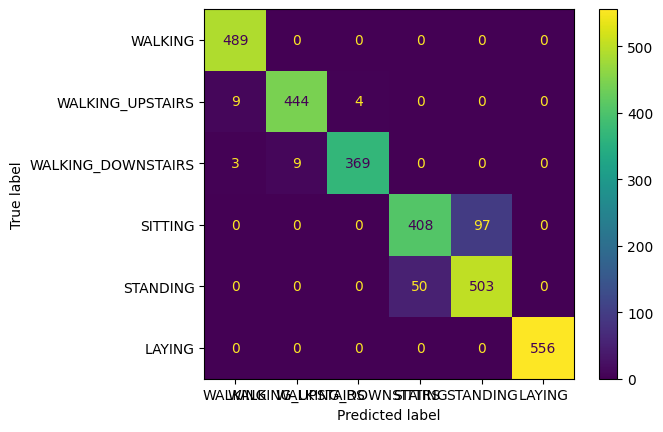

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    features_all_activities, activity, test_size=0.4
)
# Define the range of neighbors to consider
param_grid = {'n_neighbors': range(1, 21)}

# Create KNN classifier
knn = KNeighborsClassifier()

# Create GridSearchCV object
grid_search = GridSearchCV(knn, param_grid, cv=10, scoring='accuracy')

# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

# the best number of neighbors
best_k = grid_search.best_params_['n_neighbors']

# Train the final KNN model with the best k
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train, y_train)

# Predict on the test data
y_pred = final_knn.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=activity_names)
disp.plot()
plt.show()

# Regression logistique Lasso

> Ajuster et évaluer un modèle logistique Lasso sur les données avec la fonction [LogisticRegressionCV](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegressionCV.html).

In [ ]:
from sklearn.linear_model import LogisticRegressionCV
# Create LogisticRegressionCV object with Lasso regularization
lasso_logit = LogisticRegressionCV(
    cv=KFold(n_splits=10, shuffle=True),
    penalty='l1',
    solver='liblinear',
    max_iter=100
)
# Fit the model to the data
lasso_logit.fit(features_all_activities, activity)


/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [ ]:
# Evaluate the model
scores = cross_val_score(
    lasso_logit, features_all_activities, activity, cv=KFold(n_splits=10, shuffle=True, random_state=0)
)
print("Average accuracy:", np.mean(scores))

# Analyse en composantes principales sur la tableau des features.

L'analyse en composantes principales est une méthode de réduction de dimension, de visualisation et de compression de données. Elle consiste à déterminer le sous-espace vectoriel de dimension $q$ qui approche au mieux possible un nuage de points dans $\mathbb R^d$ (au sens de la projection euclidienne sur cet espace).

Les directions du sous-espace vectoriel approximant peuvent être vues comme de nouvelles variables, qui s'éxpriment comme des combinaisons linéaires des variables initiales. Par ailleurs, ces nouvelles variables, appelées **composantes principales**, sont dirigées selon les premières directions propres de la matrice de covariance empirique des données.

On représente alors les données dans le nouveau système de variables issu de l'ACP.  

![analyse en composantes principales](http://www.nlpca.org/fig_pca_principal_component_analysis.png)

Un descriptif de la fonction `sklearn.decomposition.PCA()` de la librairie scikit-learn est disponible [ici](http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

> Tracer le nuage des deux premières composantes de l'ACP en distinguant les 5 activités.
> Dans son écriture, le problème de l'ACP ignore la classification en classes d'activité. Les classes d'activités sur ces deux premières composantes sont elles bien séparées ?
> En particulier, vérifier graphiquement que les classes 3 et 4 (pour lesquelles nous avons proposé des classifieurs plus haut) ne sont pas facilement séparées par les deux premiers axes de l'APC.

PCA(n_components=5)
PCA(n_components=5)


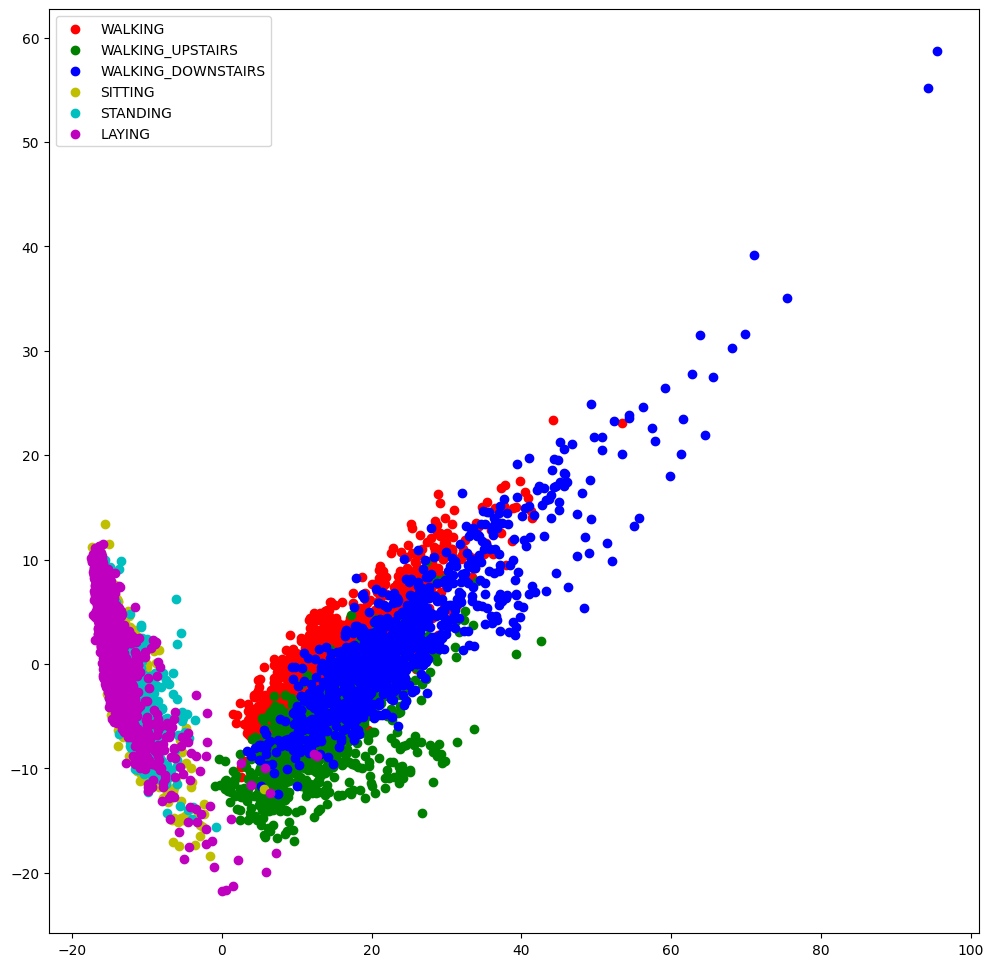

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=5)
print(pca)
from sklearn.decomposition import PCA

pca = PCA(n_components=5)
print(pca)

# Fit PCA to the data (features_nor)
pca.fit(features_nor)

# Transform the data using the fitted PCA model
features_pca = pca.transform(features_nor)

# Extract the first and second principal components
ACP0 = features_pca[:, 0]
ACP1 = features_pca[:, 1]
plt.figure(figsize=(12, 12))
for c, i, act in zip("rgbycm", range(0, 6), range(0, 6)):
    plt.scatter(ACP0[activity == act], ACP1[activity == act], c=c, label=activity_names[act])
plt.legend()
plt.show()
